# Calmaria: quando e onde a cidade fica mais barulhenta

Notebook de IA e Machine Learning da Calmaria (Global Solution 2026.2, FIAP).

## 1. Problema e pergunta de ML

Para muitas pessoas autistas, barulho alto é gatilho de sobrecarga sensorial. A Calmaria mostra no app,
para cada lugar, o nível de barulho previsto para o distrito nos próximos dias.

**Pergunta:** quantas reclamações de barulho (PSIU) cada distrito de São Paulo deve receber em cada dia, e
esse dia será de barulho **baixo, médio ou alto** para aquele distrito?

- Tipo de problema: **regressão** (contagem por distrito e dia). A contagem prevista vira um nível pelos
  tercis da história do próprio distrito.
- Dados: **reais e públicos**, SP156 da Prefeitura de São Paulo. Nada simulado.
- Limitação conhecida: a base traz só a **data** de abertura, sem a hora. Por isso o modelo responde
  "onde e em que dia"; a hora do dia vem dos sensores ESP32, na API.
- Reclamação mede **incômodo relatado**, não decibéis.

In [1]:
import os, re, unicodedata, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import holidays
from dateutil.easter import easter
from sklearn.base import clone
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_poisson_deviance, r2_score, confusion_matrix
from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
SEED = 42

# Estilo dos graficos (peca ML-01 do design)
mpl.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 150, "savefig.dpi": 150,
    "font.family": ["Atkinson Hyperlegible Next", "DejaVu Sans"],
    "font.size": 12, "axes.titlesize": 16, "axes.titleweight": "bold", "axes.labelsize": 12,
    "text.color": "#14191F", "axes.labelcolor": "#14191F",
    "xtick.color": "#4D545B", "ytick.color": "#4D545B", "axes.edgecolor": "#6B737A",
    "axes.grid": True, "grid.color": "#E0E5E9", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "#F8FBFD", "axes.facecolor": "#F8FBFD", "savefig.facecolor": "#F8FBFD",
    "axes.prop_cycle": mpl.cycler(color=["#3D5A73", "#4D545B", "#00677F"]),
})
import logging; logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
REAL, PREVISTO = "#4D545B", "#3D5A73"
NIVEL = {"BAIXO": "#437E61", "MEDIO": "#BBA15E", "ALTO": "#B2574D"}
MATRIZ = mpl.colors.LinearSegmentedColormap.from_list("calmaria", ["#F5F8FA", "#B2C9D8", "#597590", "#3C4D61"])

PASTA = Path(".")
BRUTOS = PASTA / "dados" / "brutos"
FILTRADO = PASTA / "dados" / "psiu_filtrado.csv"
FIGURAS = PASTA / "figuras"
SAIDA = PASTA / "saida"
FIGURAS.mkdir(exist_ok=True); SAIDA.mkdir(exist_ok=True)

def salva(fig, nome):
    fig.savefig(FIGURAS / nome, bbox_inches="tight")

## 2. Os dados

**Fonte:** Portal de Dados Abertos da Prefeitura de São Paulo, conjunto "Dados do SP156 - Solicitações"
(https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156). Um CSV por trimestre. Usamos **oito
trimestres, do 4º de 2024 ao 3º de 2026**. Os links de cada arquivo estão em `dados/README.md`.

**Filtro:** `Assunto == "Poluição Sonora - PSIU"`.

Cuidados que os arquivos reais exigiram (e que o código abaixo trata):
- a codificação e o separador mudam: sete arquivos vêm em `latin-1` com `;`, e o 3º trimestre de 2026 vem em
  UTF-8 com `,`. O código detecta os dois em cada arquivo (ler o UTF-8 como `latin-1` estraga o
  "Poluição" e o filtro não acha nada);
- o número de colunas muda entre arquivos (o 4º trimestre de 2024 tem a coluna "Bairro"), então as colunas
  são lidas **pelo nome normalizado**, não pela posição;
- o formato da data muda entre arquivos (`DD/MM/AAAA` em uns, `MM/DD/AAAA` em outros). Para cada arquivo, o
  código testa os dois formatos e fica com o que coloca as datas **dentro do trimestre do arquivo**;
- os arquivos têm cerca de 100 MB: leitura em pedaços de 200 mil linhas, guardando só o PSIU.

Os brutos ficam fora do Git (`dados/brutos/`); o filtrado (`dados/psiu_filtrado.csv`) entra.

In [2]:
# trimestre -> (inicio, fim) para conferir o formato da data
TRIMESTRES = {
    "4T24": ("2024-10-01", "2024-12-31"), "1T25": ("2025-01-01", "2025-03-31"),
    "2T25": ("2025-04-01", "2025-06-30"), "3T25": ("2025-07-01", "2025-09-30"),
    "4T25": ("2025-10-01", "2025-12-31"), "1T26": ("2026-01-01", "2026-03-31"),
    "2T26": ("2026-04-01", "2026-06-30"), "3T26": ("2026-07-01", "2026-09-30"),
}
ASSUNTO_PSIU = "Poluição Sonora - PSIU"

def normaliza(txt):
    txt = unicodedata.normalize("NFKD", str(txt)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", txt.lower()).strip("_")

def detecta_formato(caminho):
    # Codificacao: tenta UTF-8 no primeiro 1 MB; se quebrar, e latin-1.
    with open(caminho, "rb") as f:
        amostra = f.read(1_000_000)
    try:
        amostra.decode("utf-8")
        cod = "utf-8"
    except UnicodeDecodeError as e:
        cod = "utf-8" if e.start > len(amostra) - 4 else "latin-1"  # corte no meio de um caractere
    linha = amostra.decode(cod, errors="ignore").splitlines()[0]
    sep = ";" if linha.count(";") > linha.count(",") else ","
    return cod, sep

def filtra_psiu(caminho):
    cod, sep = detecta_formato(caminho)
    partes = []
    for pedaco in pd.read_csv(caminho, encoding=cod, sep=sep, dtype=str,
                              chunksize=200_000, on_bad_lines="skip"):
        pedaco.columns = [normaliza(c) for c in pedaco.columns]
        partes.append(pedaco[pedaco["assunto"].str.strip() == ASSUNTO_PSIU])
    df = pd.concat(partes)
    df = df[["data_de_abertura", "distrito", "prefeitura_operacional", "latitude", "longitude"]]
    return df, cod, sep

def converte_data(serie, inicio, fim):
    # Testa os dois formatos e escolhe o que deixa mais datas dentro do trimestre
    melhor = None
    for fmt in ["%d/%m/%Y", "%m/%d/%Y"]:
        datas = pd.to_datetime(serie.str.slice(0, 10), format=fmt, errors="coerce")
        dentro = datas.between(inicio, fim).mean()
        if melhor is None or dentro > melhor[1]:
            melhor = (fmt, dentro, datas)
    return melhor

if FILTRADO.exists() and not any(BRUTOS.glob("*.csv")):
    psiu = pd.read_csv(FILTRADO, parse_dates=["data"])
    print("Lido o filtrado salvo:", len(psiu), "linhas")
else:
    tabelas, resumo = [], []
    for tri, (ini, fim) in TRIMESTRES.items():
        bruto, cod, sep = filtra_psiu(BRUTOS / f"{tri}.csv")
        fmt, dentro, datas = converte_data(bruto["data_de_abertura"], ini, fim)
        bruto = bruto.assign(data=datas, trimestre=tri)
        resumo.append({"trimestre": tri, "codificacao": cod, "separador": sep, "linhas_psiu": len(bruto),
                       "formato_data": fmt,
                       "datas_no_trimestre_%": round(100 * dentro, 2)})
        tabelas.append(bruto)
    psiu = pd.concat(tabelas, ignore_index=True)
    psiu = psiu.rename(columns={"prefeitura_operacional": "subprefeitura"})
    psiu = psiu[["data", "distrito", "subprefeitura", "latitude", "longitude", "trimestre"]]
    display(pd.DataFrame(resumo))
    assert all(r["linhas_psiu"] > 1000 for r in resumo), "Algum trimestre veio vazio: conferir o arquivo"
    psiu.to_csv(FILTRADO, index=False)
    print("Salvo", FILTRADO, "com", len(psiu), "linhas")

,trimestre,codificacao,separador,linhas_psiu,formato_data,datas_no_trimestre_%
0,4T24,latin-1,;,11291,%d/%m/%Y,100.0
1,1T25,latin-1,;,10901,%d/%m/%Y,100.0
2,2T25,latin-1,;,13563,%d/%m/%Y,100.0
3,3T25,latin-1,;,12437,%d/%m/%Y,100.0
4,4T25,latin-1,;,13051,%d/%m/%Y,100.0
5,1T26,latin-1,;,12848,%d/%m/%Y,100.0
6,2T26,latin-1,;,16140,%d/%m/%Y,100.0
7,3T26,utf-8,",",14178,%m/%d/%Y,100.0


Salvo dados\psiu_filtrado.csv com 104409 linhas


In [3]:
# Limpeza: data valida, dentro do periodo, com distrito
antes = len(psiu)
psiu["distrito"] = psiu["distrito"].astype("string").str.strip().str.upper()
psiu["subprefeitura"] = psiu["subprefeitura"].astype("string").str.strip().str.upper()
psiu = psiu.dropna(subset=["data", "distrito"])
psiu = psiu[psiu["data"].between("2024-10-01", "2026-09-30")]
print(f"Linhas: {antes} -> {len(psiu)} ({antes - len(psiu)} descartadas por data ou distrito vazio)")
print("Distritos:", psiu["distrito"].nunique(), "| Período:", psiu["data"].min().date(), "a", psiu["data"].max().date())
psiu.head()

Linhas: 104409 -> 104369 (40 descartadas por data ou distrito vazio)
Distritos: 96 | Período: 2024-10-01 a 2026-09-30


,data,distrito,subprefeitura,latitude,longitude,trimestre
0,2024-11-02,SANTA CECILIA,SE,-23.5314296,-46.6545147,4T24
1,2024-11-07,SACOMA,IPIRANGA,-23.6403702,-46.6132185,4T24
2,2024-11-14,IGUATEMI,SAO MATEUS,-23.6145409,-46.432538,4T24
3,2024-11-21,JARDIM SAO LUIS,M BOI MIRIM,-23.6699383,-46.7430884,4T24
4,2024-11-21,ITAQUERA,ITAQUERA,-23.5301911,-46.4687324,4T24


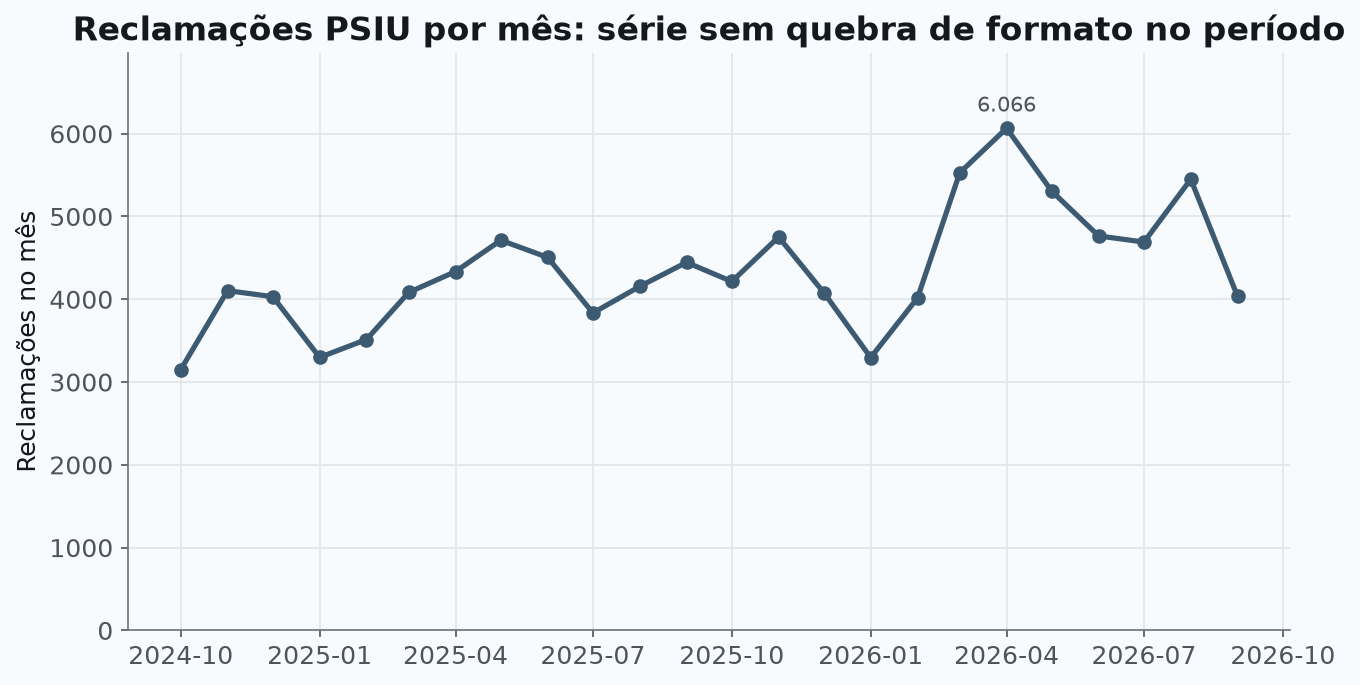

data,2024-10-01,2024-11-01,2024-12-01,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01,2026-09-01
reclamacoes,3151,4104,4031,3298,3514,4083,4335,4713,4506,3835,4155,4446,4215,4752,4079,3296,4016,5529,6066,5304,4765,4691,5450,4035


In [4]:
# Total mensal: procurar quebras de serie antes de juntar (peca ML-02)
mensal = psiu.set_index("data").resample("MS").size()
fig, ax = plt.subplots()
ax.plot(mensal.index, mensal.values, color="#3D5A73", linewidth=2.5, marker="o")
ax.set_ylim(0, mensal.max() * 1.15)
media = mensal.mean()
for d, v in mensal.items():
    if abs(v - media) > 0.35 * media:
        ax.annotate(f"{v:,}".replace(",", "."), (d, v), textcoords="offset points", xytext=(0, 8),
                    ha="center", fontsize=10, color="#4D545B")
ax.set_title("Reclamações PSIU por mês: série sem quebra de formato no período")
ax.set_ylabel("Reclamações no mês"); ax.set_xlabel("")
salva(fig, "ml02_total_mensal.png"); plt.show()
mensal.rename("reclamacoes").to_frame().T

## 3. Exploração

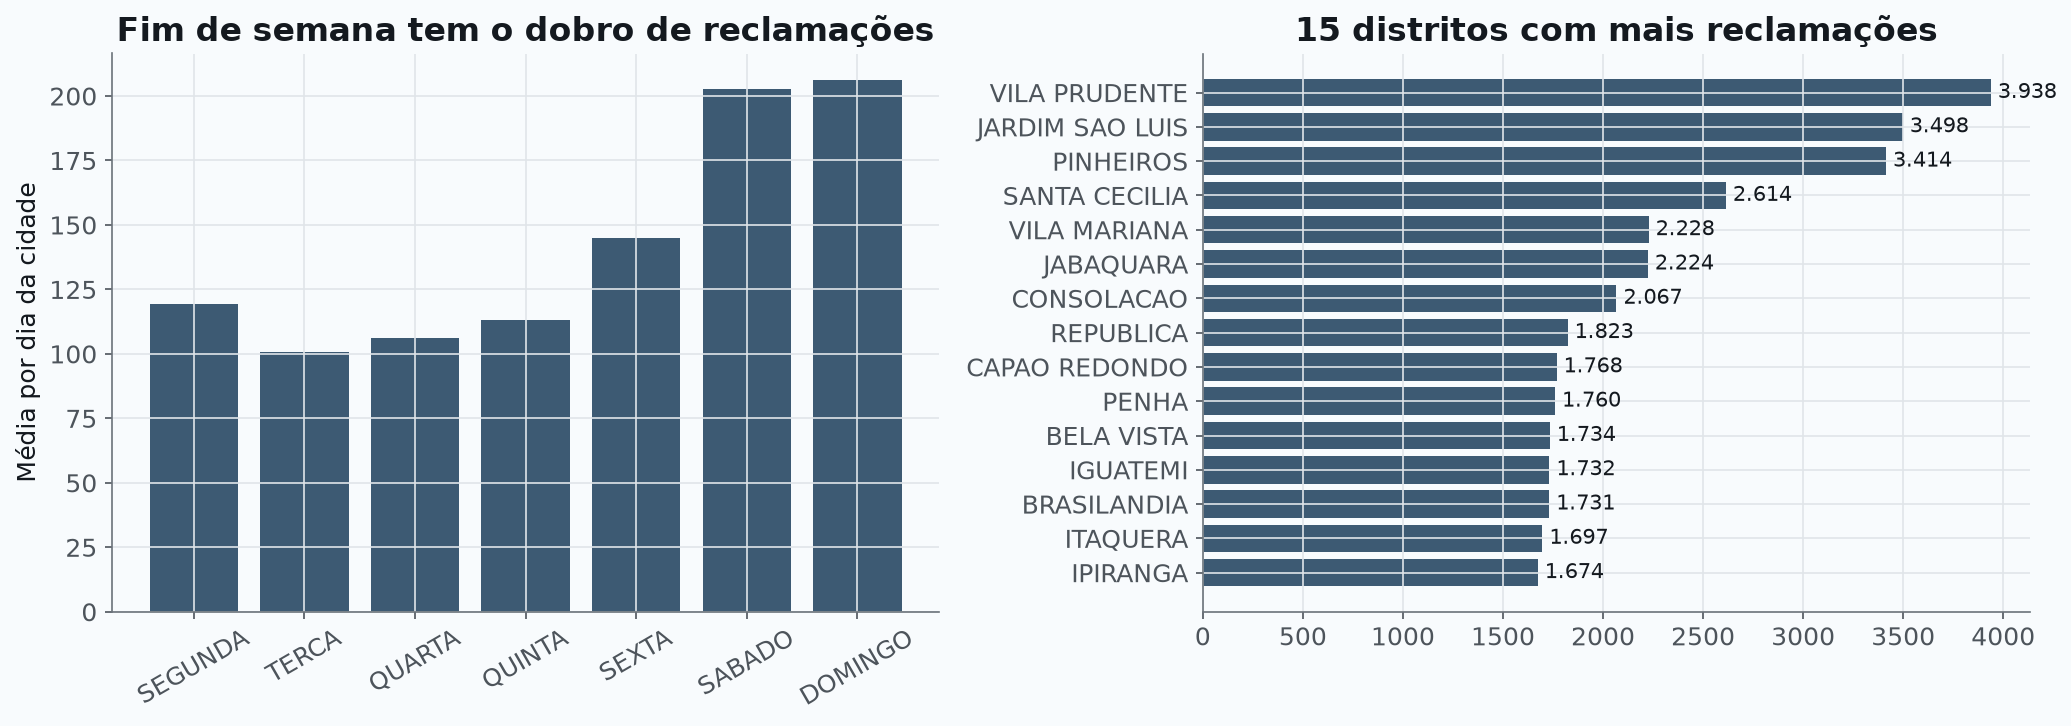

Posição da Consolação: 7
Posição da Bela Vista: 11


In [5]:
DIAS = ["SEGUNDA", "TERCA", "QUARTA", "QUINTA", "SEXTA", "SABADO", "DOMINGO"]
por_dia = psiu["data"].dt.day_of_week.value_counts().sort_index()
n_semanas = psiu["data"].dt.to_period("W").nunique()
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
axs[0].bar(DIAS, por_dia.values / n_semanas, color="#3D5A73")
axs[0].set_title("Fim de semana tem o dobro de reclamações"); axs[0].set_ylabel("Média por dia da cidade")
axs[0].tick_params(axis="x", rotation=30)
top = psiu["distrito"].value_counts().head(15).sort_values()
axs[1].barh(top.index, top.values, color="#3D5A73")
axs[1].set_title("15 distritos com mais reclamações")
for i, v in enumerate(top.values):
    axs[1].text(v, i, f" {v:,}".replace(",", "."), va="center", fontsize=10)
fig.tight_layout(); salva(fig, "exploracao.png"); plt.show()
print("Posição da Consolação:", list(psiu["distrito"].value_counts().index).index("CONSOLACAO") + 1)
print("Posição da Bela Vista:", list(psiu["distrito"].value_counts().index).index("BELA VISTA") + 1)

In [6]:
por_mes = psiu.groupby(psiu["data"].dt.month).size()
print("Reclamações por mês do ano (soma do período):")
por_mes.rename(index=dict(enumerate(["jan","fev","mar","abr","mai","jun","jul","ago","set","out","nov","dez"], 1))).to_frame("reclamacoes").T

Reclamações por mês do ano (soma do período):


data,jan,fev,mar,abr,mai,jun,jul,ago,set,out,nov,dez
reclamacoes,6594,7530,9612,10401,10017,9271,8526,9605,8481,7366,8856,8110


## 4. Preparação

1. **Agregação** por distrito e dia: a contagem é o alvo.
2. **Completar com zero** (produto cartesiano de distritos e datas): dia sem reclamação também é informação.
3. **Atributos** de calendário (dia da semana, fim de semana, mês, dia do mês, feriado, véspera de feriado),
   do lugar (distrito e subprefeitura codificados) e as **médias históricas do distrito**, calculadas
   **só com os dados de treino** dentro do pipeline (a cada dobra da validação cruzada elas são recalculadas
   só com a parte de treino daquela dobra).
4. Ficam **de fora** atributos de "ontem" e "semana passada": o app precisa prever semanas à frente, e o
   SP156 publica os dados por trimestre, com atraso.
5. **Divisão por tempo**: treino do 4º tri de 2024 ao 1º tri de 2026; teste do 2º e 3º tri de 2026.
   Divisão aleatória misturaria dias vizinhos entre treino e teste e daria um resultado bom demais.

In [7]:
datas = pd.date_range("2024-10-01", "2026-09-30", freq="D")
distritos = sorted(psiu["distrito"].unique())
grade = pd.MultiIndex.from_product([distritos, datas], names=["distrito", "data"]).to_frame(index=False)
contagem = psiu.groupby(["distrito", "data"]).size().rename("reclamacoes").reset_index()
base = grade.merge(contagem, how="left", on=["distrito", "data"]).fillna({"reclamacoes": 0})
base["reclamacoes"] = base["reclamacoes"].astype(int)

# subprefeitura de cada distrito: a mais frequente
sub_do_distrito = psiu.groupby("distrito")["subprefeitura"].agg(lambda s: s.mode().iat[0])
base["subprefeitura"] = base["distrito"].map(sub_do_distrito)
print(base.shape, "| dias com zero:", f"{(base['reclamacoes'] == 0).mean():.1%}")
base.describe()

(70080, 4) | dias com zero: 40.0%


,data,reclamacoes
count,70080,70080.000000
mean,2025-09-30 12:00:00,1.489284
min,2024-10-01 00:00:00,0.000000
25%,2025-04-01 00:00:00,0.000000
50%,2025-09-30 12:00:00,1.000000
75%,2026-04-01 00:00:00,2.000000
max,2026-09-30 00:00:00,144.000000
std,NaN,2.666181


In [8]:
def feriados_sp(anos):
    f = holidays.Brazil(subdiv="SP", years=anos)
    dias = {pd.Timestamp(d): n for d, n in f.items()}
    for ano in anos:  # municipais de Sao Paulo
        dias[pd.Timestamp(f"{ano}-01-25")] = "Aniversário de São Paulo"
        pascoa = pd.Timestamp(easter(ano))
        dias[pascoa + pd.Timedelta(days=60)] = "Corpus Christi"
    return dias

FERIADOS = feriados_sp([2024, 2025, 2026])

def atributos_calendario(df):
    d = df["data"]
    out = df.copy()
    out["dia_semana"] = d.dt.day_of_week
    out["fim_de_semana"] = (out["dia_semana"] >= 5).astype(int)
    out["mes"] = d.dt.month
    out["dia_mes"] = d.dt.day
    out["feriado"] = d.isin(list(FERIADOS)).astype(int)
    out["vespera_feriado"] = (d + pd.Timedelta(days=1)).isin(list(FERIADOS)).astype(int)
    out["distrito_cod"] = pd.Categorical(out["distrito"], categories=distritos).codes
    out["subprefeitura_cod"] = pd.Categorical(out["subprefeitura"], categories=sorted(sub_do_distrito.unique())).codes
    return out

base = atributos_calendario(base).sort_values(["data", "distrito"]).reset_index(drop=True)
print("Feriados no período:", sum(1 for d in FERIADOS if datas[0] <= d <= datas[-1]))
base.head()

Feriados no período: 26


,distrito,data,reclamacoes,subprefeitura,dia_semana,fim_de_semana,mes,dia_mes,feriado,vespera_feriado,distrito_cod,subprefeitura_cod
0,AGUA RASA,2024-10-01,0,MOOCA,1,0,10,1,0,0,0,18
1,ALTO DE PINHEIROS,2024-10-01,0,PINHEIROS,1,0,10,1,0,0,1,22
2,ANHANGUERA,2024-10-01,0,PERUS,1,0,10,1,0,0,2,21
3,ARICANDUVA,2024-10-01,0,ARICANDUVA-FORMOSA-CARRAO,1,0,10,1,0,0,3,0
4,ARTUR ALVIM,2024-10-01,0,PENHA,1,0,10,1,0,0,4,20


In [9]:
class MediasDoDistrito(BaseEstimator, TransformerMixin):
    # Acrescenta a media historica do distrito e a do distrito naquele dia da semana.
    # As medias sao aprendidas no fit (so com o treino) e aplicadas no transform.
    def fit(self, X, y):
        tmp = X[["distrito_cod", "dia_semana"]].assign(y=np.asarray(y))
        self.geral_ = tmp["y"].mean()
        self.dist_ = tmp.groupby("distrito_cod")["y"].mean()
        self.dist_dia_ = tmp.groupby(["distrito_cod", "dia_semana"])["y"].mean()
        return self
    def transform(self, X):
        X = X.copy()
        X["media_distrito"] = X["distrito_cod"].map(self.dist_).fillna(self.geral_)
        chave = pd.MultiIndex.from_arrays([X["distrito_cod"], X["dia_semana"]])
        X["media_distrito_dia"] = self.dist_dia_.reindex(chave).to_numpy()
        X["media_distrito_dia"] = X["media_distrito_dia"].fillna(X["media_distrito"])
        return X

ATRIBUTOS = ["dia_semana", "fim_de_semana", "mes", "dia_mes", "feriado", "vespera_feriado",
             "distrito_cod", "subprefeitura_cod"]
ALVO = "reclamacoes"

treino = base[base["data"] <= "2026-03-31"].reset_index(drop=True)
teste = base[base["data"] >= "2026-04-01"].reset_index(drop=True)
X_tr, y_tr = treino[ATRIBUTOS], treino[ALVO]
X_te, y_te = teste[ATRIBUTOS], teste[ALVO]
print(f"Treino: {treino['data'].min().date()} a {treino['data'].max().date()} ({len(treino):,} linhas)")
print(f"Teste:  {teste['data'].min().date()} a {teste['data'].max().date()} ({len(teste):,} linhas)")

Treino: 2024-10-01 a 2026-03-31 (52,512 linhas)
Teste:  2026-04-01 a 2026-09-30 (17,568 linhas)


## 5. Linha de base (sem ML)

A média histórica do distrito naquele dia da semana, calculada no treino. Os modelos só valem se forem
melhores que ela.

In [10]:
def metricas(y, p):
    # Deviance de Poisson: a metrica propria para contagem (penaliza prever 0 quando houve reclamacao).
    return {"MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** 0.5, "R2": r2_score(y, p),
            "Deviance": mean_poisson_deviance(y, np.clip(p, 1e-3, None))}

linha_base = MediasDoDistrito().fit(X_tr, y_tr)
p_base_tr = linha_base.transform(X_tr)["media_distrito_dia"]
p_base_te = linha_base.transform(X_te)["media_distrito_dia"]
resultados = {"Linha de base": {"treino": metricas(y_tr, p_base_tr), "teste": metricas(y_te, p_base_te)}}
pd.DataFrame(resultados["Linha de base"]).T.round(3)

,MAE,RMSE,R2,Deviance
treino,1.159,2.186,0.174,1.764
teste,1.331,3.062,0.147,2.263


## 6. Random Forest com busca de hiperparâmetros

`GridSearchCV` com `TimeSeriesSplit(n_splits=5)` **só no treino**: cada dobra valida em um período posterior ao
que treinou, como no uso real. 18 combinações de `n_estimators`, `max_depth` e `min_samples_leaf`. Cada árvore usa metade das linhas
(`max_samples=0.5`) e 60% dos atributos por divisão: deixa o treino mais rápido e as árvores mais diferentes
entre si, o que também reduz o overfitting.

In [11]:
cv = TimeSeriesSplit(n_splits=5)

def tabela_cv(busca, params):
    r = pd.DataFrame(busca.cv_results_)
    cols = [f"param_{p}" for p in params]
    t = r[cols + ["mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]].copy()
    t["MAE_treino_cv"] = -t.pop("mean_train_score")
    t["MAE_validacao_cv"] = -t.pop("mean_test_score")
    t.columns = [c.replace("param_modelo__", "") for c in t.columns]
    return t.sort_values("rank_test_score").round(4).reset_index(drop=True)

pipe_rf = Pipeline([("medias", MediasDoDistrito()),
                    ("modelo", RandomForestRegressor(random_state=SEED, n_jobs=-1, max_features=0.6,
                                                     max_samples=0.5))])
grade_rf = {"modelo__n_estimators": [100, 300], "modelo__max_depth": [8, 16, None],
            "modelo__min_samples_leaf": [1, 5, 20]}
busca_rf = GridSearchCV(pipe_rf, grade_rf, cv=cv, scoring="neg_mean_absolute_error",
                        return_train_score=True, n_jobs=1)
busca_rf.fit(X_tr, y_tr)
print("Melhor Random Forest:", busca_rf.best_params_)
tabela_rf = tabela_cv(busca_rf, grade_rf)
tabela_rf

Melhor Random Forest: {'modelo__max_depth': 16, 'modelo__min_samples_leaf': 20, 'modelo__n_estimators': 100}


,n_estimators,max_depth,min_samples_leaf,std_test_score,rank_test_score,MAE_treino_cv,MAE_validacao_cv
0,100,16,20,0.0678,1,1.0151,1.1624
1,100,None,20,0.0678,2,1.0145,1.1624
2,300,None,20,0.0678,3,1.0143,1.1626
3,300,16,20,0.0679,4,1.0148,1.1627
4,300,8,20,0.0684,5,1.0364,1.1636
5,100,8,20,0.0684,6,1.0367,1.1638
6,100,8,5,0.0679,7,1.0235,1.1644
7,300,8,5,0.0678,8,1.0233,1.1644
8,300,8,1,0.0657,9,1.0133,1.1677
9,100,8,1,0.0654,10,1.0137,1.1683


## 7. XGBoost com busca de hiperparâmetros

27 combinações de `n_estimators`, `max_depth` e `learning_rate`, cada uma com duas funções de perda:
`reg:squarederror` (erro quadrático) e `count:poisson` (própria para contagem). 54 combinações no total.

In [12]:
pipe_xgb = Pipeline([("medias", MediasDoDistrito()),
                     ("modelo", XGBRegressor(random_state=SEED, n_jobs=-1, tree_method="hist", subsample=0.8,
                                             colsample_bytree=0.8))])
grade_xgb = {"modelo__n_estimators": [100, 300, 600], "modelo__max_depth": [3, 5, 8],
             "modelo__learning_rate": [0.03, 0.1, 0.3],
             "modelo__objective": ["reg:squarederror", "count:poisson"]}
busca_xgb = GridSearchCV(pipe_xgb, grade_xgb, cv=cv, scoring="neg_mean_absolute_error",
                         return_train_score=True, n_jobs=1)
busca_xgb.fit(X_tr, y_tr)
print("Melhor XGBoost:", busca_xgb.best_params_)
tabela_xgb = tabela_cv(busca_xgb, grade_xgb)
tabela_xgb

Melhor XGBoost: {'modelo__learning_rate': 0.03, 'modelo__max_depth': 3, 'modelo__n_estimators': 600, 'modelo__objective': 'count:poisson'}


,n_estimators,max_depth,learning_rate,objective,std_test_score,rank_test_score,MAE_treino_cv,MAE_validacao_cv
0,600,3,0.03,count:poisson,0.0670,1,1.0356,1.1502
1,100,3,0.30,count:poisson,0.0647,2,1.0262,1.1510
2,300,5,0.03,count:poisson,0.0663,3,1.0232,1.1526
3,300,3,0.03,reg:squarederror,0.0680,4,1.0387,1.1528
4,100,3,0.10,reg:squarederror,0.0668,5,1.0366,1.1532
5,300,3,0.10,count:poisson,0.0663,6,1.0265,1.1534
6,100,5,0.10,count:poisson,0.0663,7,1.0197,1.1537
7,100,3,0.10,count:poisson,0.0684,8,1.0470,1.1540
8,600,3,0.03,reg:squarederror,0.0669,9,1.0290,1.1549
9,600,5,0.03,count:poisson,0.0657,10,0.9946,1.1551


## 8. Resultados em treino e teste

In [13]:
modelos = {"Random Forest": busca_rf.best_estimator_, "XGBoost": busca_xgb.best_estimator_}
previsoes_teste = {"Linha de base": p_base_te.to_numpy()}
for nome, m in modelos.items():
    p_tr = np.clip(m.predict(X_tr), 0, None)
    p_te = np.clip(m.predict(X_te), 0, None)
    previsoes_teste[nome] = p_te
    resultados[nome] = {"treino": metricas(y_tr, p_tr), "teste": metricas(y_te, p_te)}

tabela_final = pd.concat({n: pd.DataFrame(r).T for n, r in resultados.items()}).unstack(level=1)
tabela_final.columns = [f"{m} {c}" for m, c in tabela_final.columns]
tabela_final = tabela_final[["MAE treino", "MAE teste", "RMSE treino", "RMSE teste", "R2 treino", "R2 teste",
                             "Deviance treino", "Deviance teste"]]
tabela_final.round(3)

,MAE treino,MAE teste,RMSE treino,RMSE teste,R2 treino,R2 teste,Deviance treino,Deviance teste
Linha de base,1.159,1.331,2.186,3.062,0.174,0.147,1.764,2.263
Random Forest,1.107,1.336,2.110,3.074,0.231,0.140,1.606,2.271
XGBoost,1.140,1.334,2.123,3.067,0.221,0.144,1.702,2.250


In [14]:
# A escolha entre os dois modelos usa a validacao cruzada (so treino), nao o teste.
melhor_nome = "XGBoost" if busca_xgb.best_score_ >= busca_rf.best_score_ else "Random Forest"
melhor = modelos[melhor_nome]
print(f"Modelo escolhido pela validação cruzada: {melhor_nome}")
for m in ["MAE", "Deviance"]:
    b, x = resultados["Linha de base"]["teste"][m], resultados[melhor_nome]["teste"][m]
    print(f"{m} no teste: linha de base {b:.3f} | {melhor_nome} {x:.3f} | diferença {100 * (x - b) / b:+.1f}%")

# Nos distritos do prototipo
linhas = []
for dist in ["CONSOLACAO", "BELA VISTA"]:
    k = (teste["distrito"] == dist).to_numpy()
    linhas.append({"distrito": dist,
                   "MAE linha de base": mean_absolute_error(y_te[k], previsoes_teste["Linha de base"][k]),
                   f"MAE {melhor_nome}": mean_absolute_error(y_te[k], previsoes_teste[melhor_nome][k]),
                   "média real por dia": y_te[k].mean()})
pd.DataFrame(linhas).round(3)

Modelo escolhido pela validação cruzada: XGBoost
MAE no teste: linha de base 1.331 | XGBoost 1.334 | diferença +0.3%
Deviance no teste: linha de base 2.263 | XGBoost 2.250 | diferença -0.6%


,distrito,MAE linha de base,MAE XGBoost,média real por dia
0,CONSOLACAO,3.407,3.366,4.962
1,BELA VISTA,1.652,1.639,2.672


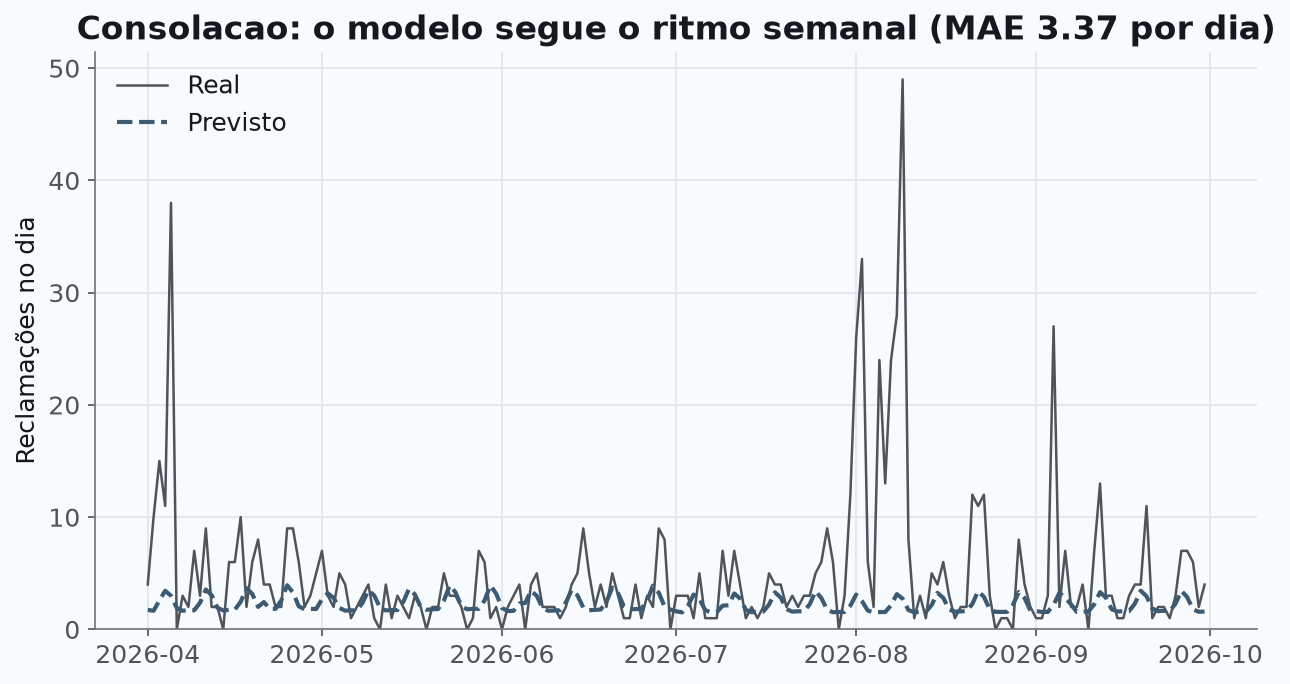

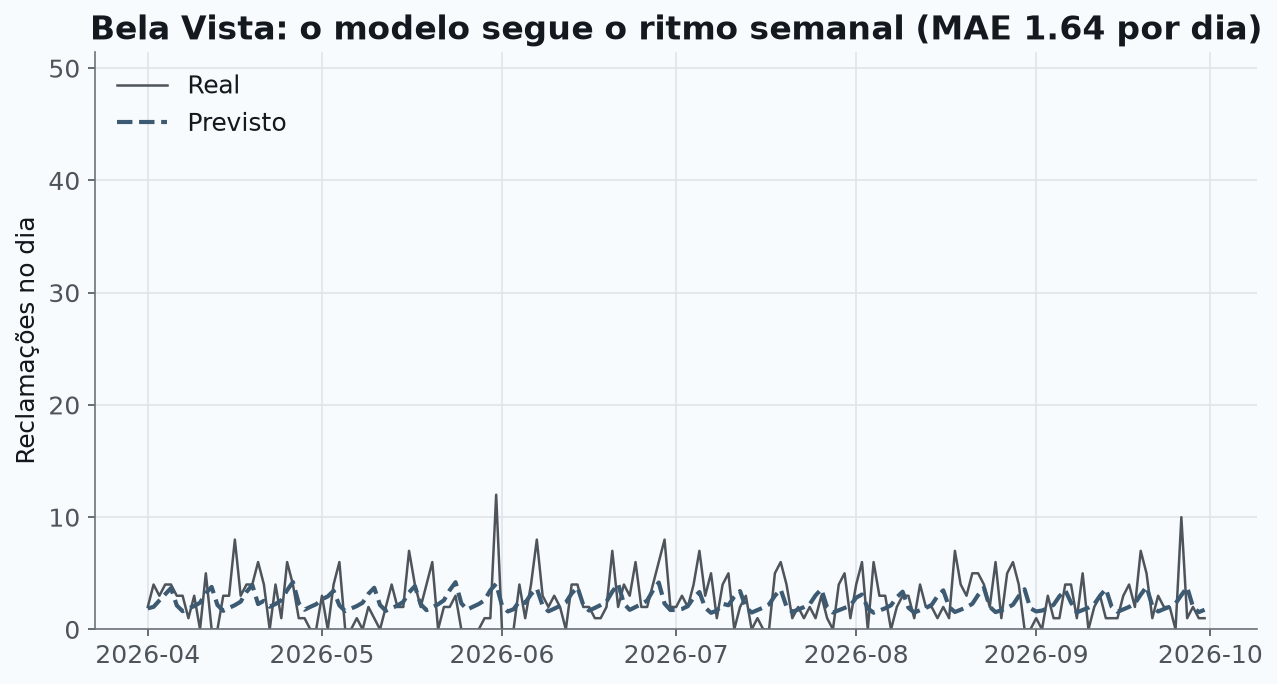

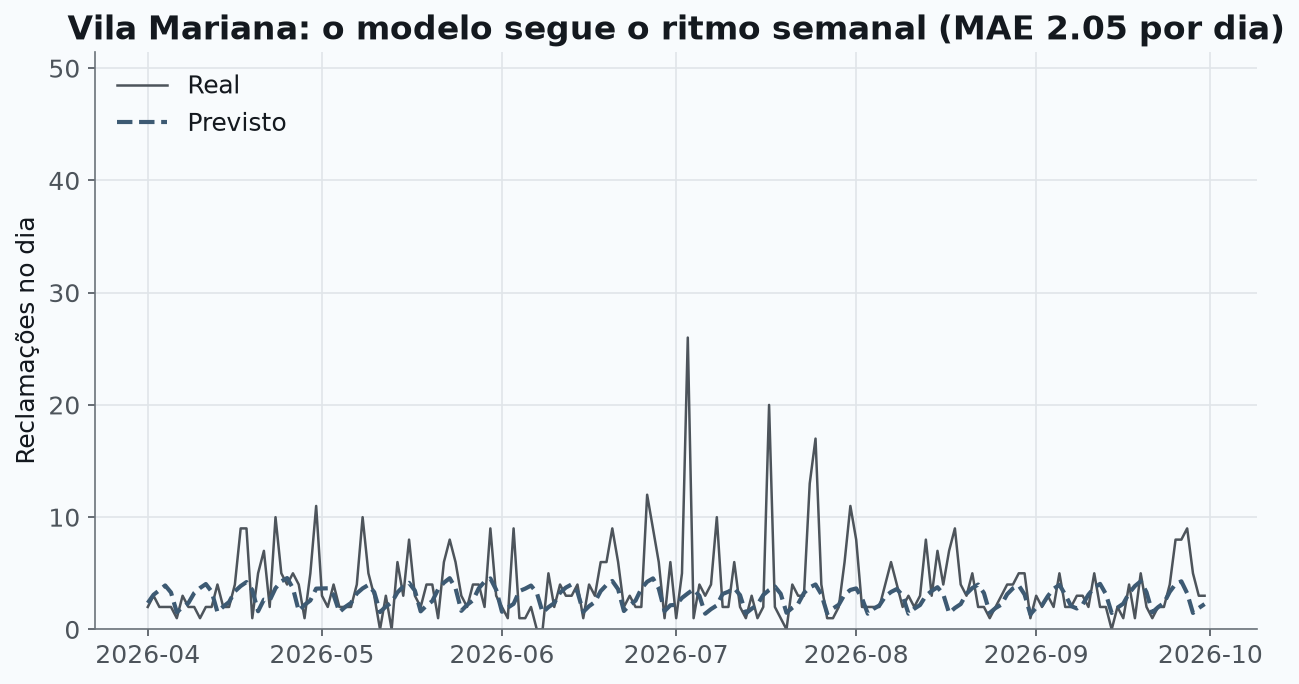

In [15]:
# Previsto contra real no teste (peca ML-03): mesma escala no eixo y
RESIDENCIAL = "VILA MARIANA" if "VILA MARIANA" in distritos else distritos[0]
mostrar = ["CONSOLACAO", "BELA VISTA", RESIDENCIAL]
teste_plot = teste.assign(previsto=previsoes_teste[melhor_nome])
ymax = teste_plot[teste_plot["distrito"].isin(mostrar)][["reclamacoes", "previsto"]].max().max() * 1.05
for dist in mostrar:
    t = teste_plot[teste_plot["distrito"] == dist]
    fig, ax = plt.subplots()
    ax.plot(t["data"], t["reclamacoes"], color=REAL, linewidth=1.2, label="Real")
    ax.plot(t["data"], t["previsto"], color=PREVISTO, linewidth=2, linestyle="--", label="Previsto")
    mae = mean_absolute_error(t["reclamacoes"], t["previsto"])
    ax.set_title(f"{dist.title()}: o modelo segue o ritmo semanal (MAE {mae:.2f} por dia)")
    ax.set_ylim(0, ymax); ax.set_ylabel("Reclamações no dia"); ax.legend(loc="upper left", frameon=False)
    salva(fig, f"ml03_previsto_real_{normaliza(dist)}.png"); plt.show()

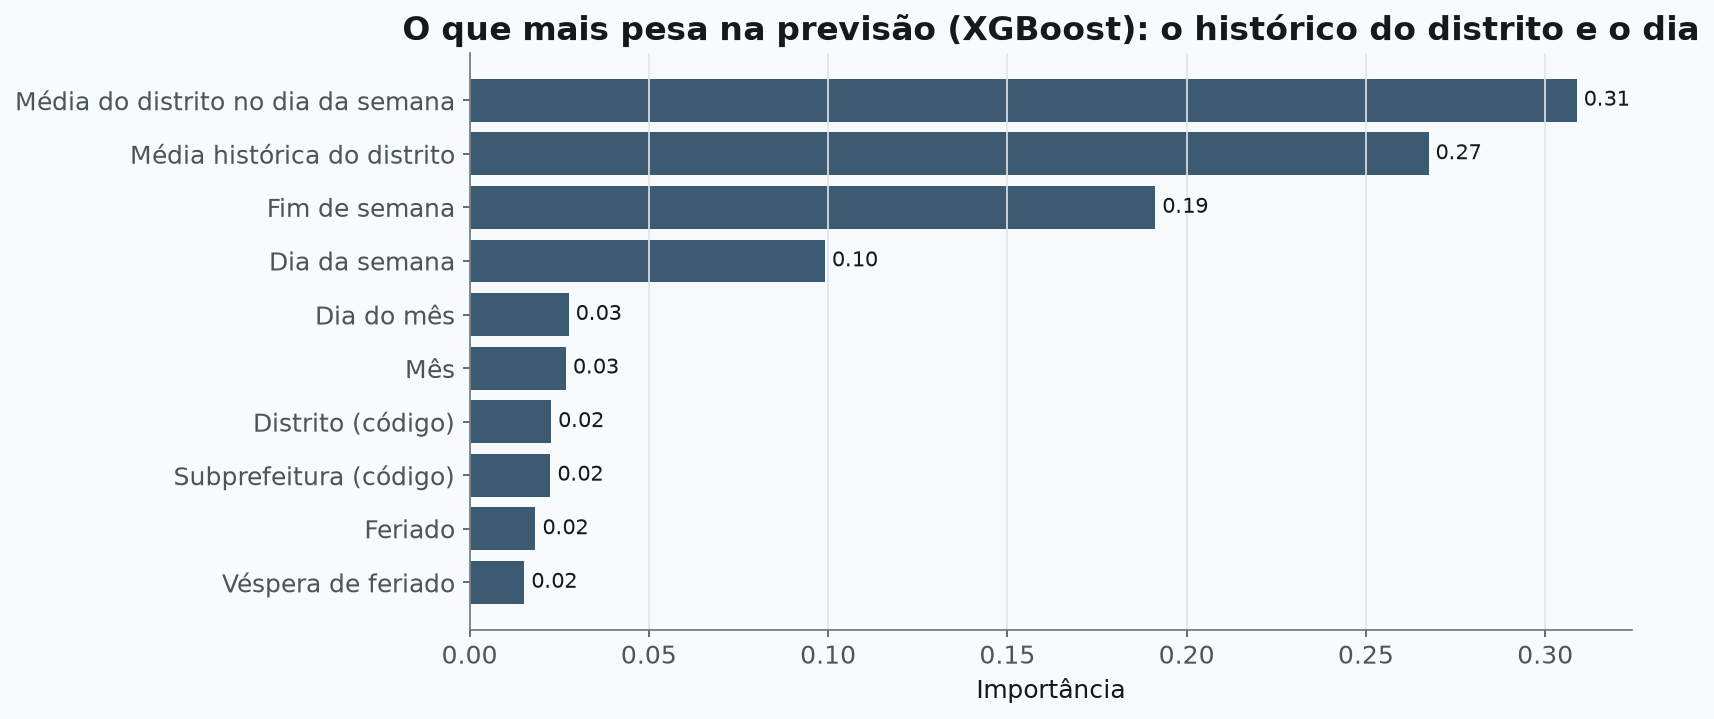

In [16]:
# Importancia dos atributos (peca ML-04)
NOMES = {"dia_semana": "Dia da semana", "fim_de_semana": "Fim de semana", "mes": "Mês", "dia_mes": "Dia do mês",
         "feriado": "Feriado", "vespera_feriado": "Véspera de feriado", "distrito_cod": "Distrito (código)",
         "subprefeitura_cod": "Subprefeitura (código)", "media_distrito": "Média histórica do distrito",
         "media_distrito_dia": "Média do distrito no dia da semana"}
cols_modelo = ATRIBUTOS + ["media_distrito", "media_distrito_dia"]
imp = pd.Series(melhor.named_steps["modelo"].feature_importances_, index=[NOMES[c] for c in cols_modelo]).sort_values()
fig, ax = plt.subplots()
ax.barh(imp.index, imp.values, color="#3D5A73")
for i, v in enumerate(imp.values):
    ax.text(v, i, f" {v:.2f}", va="center", fontsize=10)
ax.set_title(f"O que mais pesa na previsão ({melhor_nome}): o histórico do distrito e o dia")
ax.set_xlabel("Importância"); ax.grid(axis="y", visible=False)
salva(fig, "ml04_importancia.png"); plt.show()

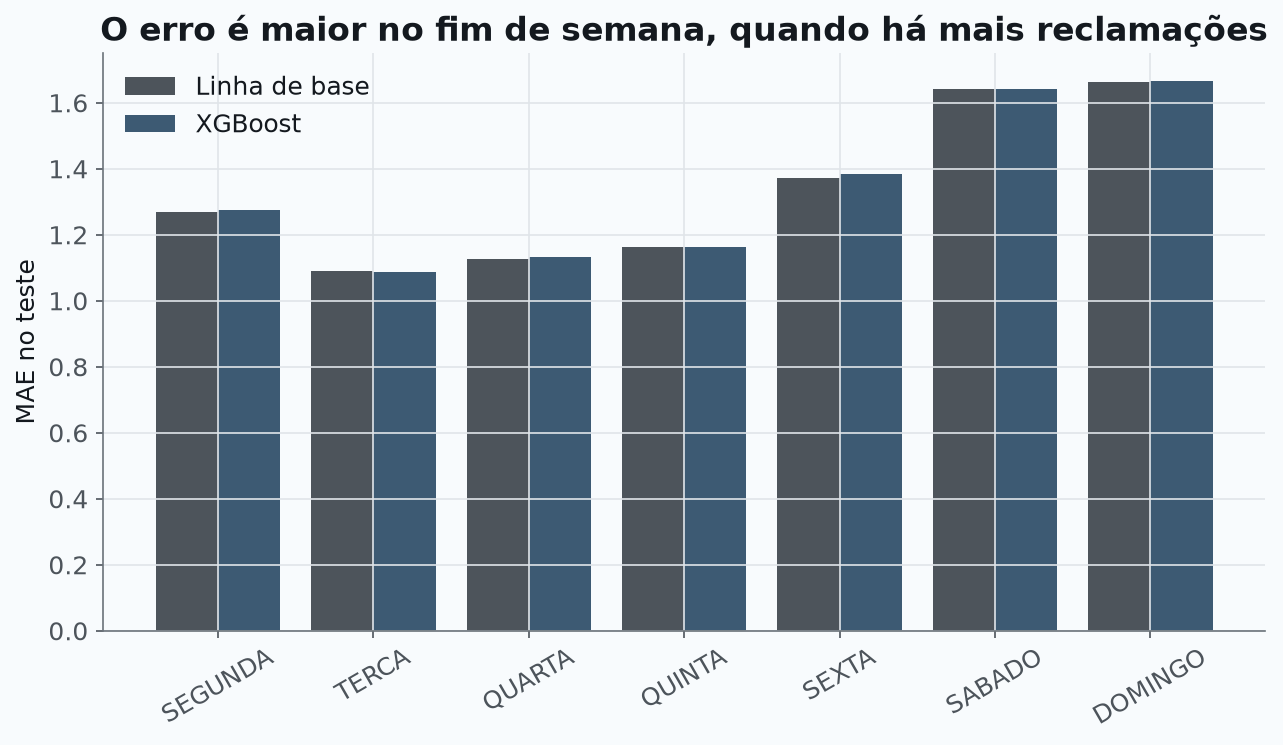

dia_semana,0,1,2,3,4,5,6
erro,1.274,1.086,1.131,1.164,1.384,1.642,1.667
erro_base,1.270,1.089,1.127,1.164,1.371,1.641,1.662


In [17]:
# Erro por dia da semana no teste
erro_dia = (teste.assign(erro=np.abs(previsoes_teste[melhor_nome] - teste["reclamacoes"]),
                         erro_base=np.abs(previsoes_teste["Linha de base"] - teste["reclamacoes"]))
            .groupby("dia_semana")[["erro", "erro_base"]].mean())
fig, ax = plt.subplots()
x = np.arange(7)
ax.bar(x - 0.2, erro_dia["erro_base"], 0.4, color="#4D545B", label="Linha de base")
ax.bar(x + 0.2, erro_dia["erro"], 0.4, color="#3D5A73", label=melhor_nome)
ax.set_xticks(x, DIAS, rotation=30); ax.set_ylabel("MAE no teste")
ax.set_title("O erro é maior no fim de semana, quando há mais reclamações"); ax.legend(frameon=False)
salva(fig, "erro_por_dia.png"); plt.show()
erro_dia.T.round(3)

### Acerto do nível (o que o app usa)

Cada distrito tem os seus **tercis**, calculados com a história de treino: abaixo do 1º tercil é BAIXO,
entre o 1º e o 2º é MEDIO, acima é ALTO. Os cortes vêm das contagens reais do distrito; o valor real e o
previsto de cada dia do teste são convertidos com os mesmos cortes e comparados.

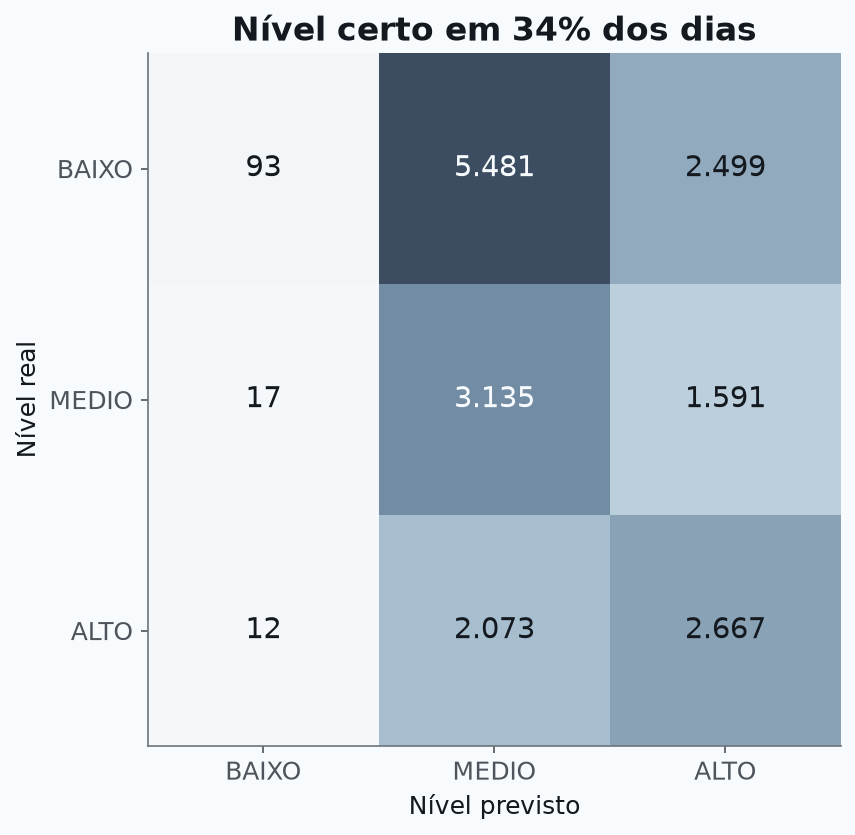

Acerto do nível: XGBoost 33.6% | linha de base 34.2% | ao acaso 33,3%
Só Consolação e Bela Vista: XGBoost 45.9% | linha de base 42.3%
Erros de dois níveis (BAIXO <-> ALTO): 14.3%


In [18]:
cortes = treino.groupby("distrito")["reclamacoes"].quantile([1/3, 2/3]).unstack()
cortes.columns = ["t1", "t2"]

def nivel(valores, dist):
    c = cortes.loc[dist].to_numpy()
    t1, t2 = c[:, 0], c[:, 1]
    return np.where(valores <= t1, "BAIXO", np.where(valores <= t2, "MEDIO", "ALTO"))

ORDEM = ["BAIXO", "MEDIO", "ALTO"]
nivel_real = nivel(teste["reclamacoes"].to_numpy(), teste["distrito"])
nivel_prev = nivel(previsoes_teste[melhor_nome], teste["distrito"])
nivel_base = nivel(previsoes_teste["Linha de base"], teste["distrito"])
cm = confusion_matrix(nivel_real, nivel_prev, labels=ORDEM)
acerto, acerto_base = (nivel_real == nivel_prev).mean(), (nivel_real == nivel_base).mean()

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(cm, cmap=MATRIZ); ax.grid(False)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]:,}".replace(",", "."), ha="center", va="center", fontsize=14,
                color="#F8FBFD" if cm[i, j] > cm.max() * 0.55 else "#14191F")
ax.set_xticks(range(3), ORDEM); ax.set_yticks(range(3), ORDEM)
ax.set_xlabel("Nível previsto"); ax.set_ylabel("Nível real")
ax.set_title(f"Nível certo em {acerto:.0%} dos dias")
salva(fig, "ml05_matriz_confusao.png"); plt.show()
print(f"Acerto do nível: {melhor_nome} {acerto:.1%} | linha de base {acerto_base:.1%} | ao acaso 33,3%")
cons = teste["distrito"].isin(["CONSOLACAO", "BELA VISTA"]).to_numpy()
print(f"Só Consolação e Bela Vista: {melhor_nome} {(nivel_real[cons] == nivel_prev[cons]).mean():.1%} | "
      f"linha de base {(nivel_real[cons] == nivel_base[cons]).mean():.1%}")
# Errar por um nivel (BAIXO <-> MEDIO) e menos grave que errar por dois (BAIXO <-> ALTO)
ordem = {"BAIXO": 0, "MEDIO": 1, "ALTO": 2}
dist2 = np.abs(np.vectorize(ordem.get)(nivel_real) - np.vectorize(ordem.get)(nivel_prev)) == 2
print(f"Erros de dois níveis (BAIXO <-> ALTO): {dist2.mean():.1%}")

### O que a comparação mostra

O ganho do modelo sobre a linha de base é **pequeno**. Com média de 1,5 reclamação por distrito por dia e
40% dos dias com zero, o ruído diário é grande, e quase todo o sinal previsível está em "qual distrito" e
"qual dia da semana", que a linha de base já usa. O XGBoost melhora um pouco na deviance de Poisson (a
métrica própria para contagem) e nos distritos do protótipo; no MAE geral, empata. Observação: o MAE favorece
a **mediana**, e a mediana histórica do distrito no dia da semana teria MAE menor que qualquer modelo de
média, mas prevê 0 em muitos dias e não serve para classificar o nível. Por isso a escolha não é feita só
pelo MAE.

## 9. Overfitting

Comparamos o erro de treino e o de validação da busca. Quando o modelo decora o treino (árvore muito funda,
folha com uma linha só), o MAE de treino cai muito e o de validação não acompanha.

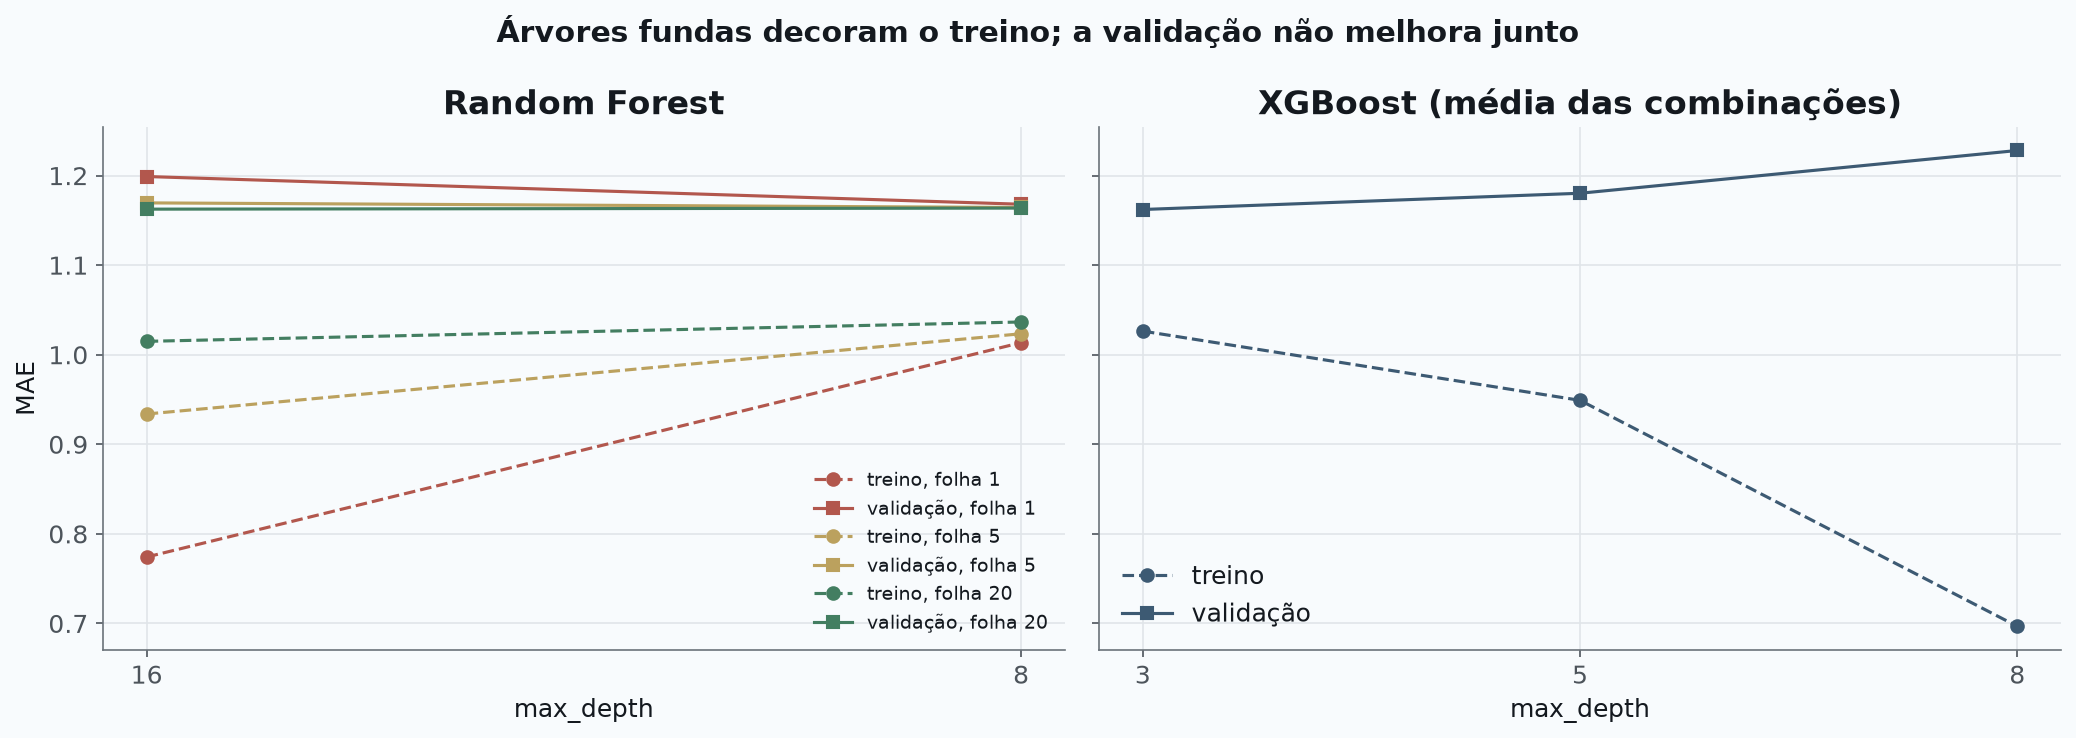

Random Forest: MAE treino 1.107 | teste 1.336 | diferença +0.229
XGBoost: MAE treino 1.140 | teste 1.334 | diferença +0.194


In [19]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
r = pd.DataFrame(busca_rf.cv_results_)
r["prof"] = r["param_modelo__max_depth"].astype(str).replace("None", "sem limite")
g = r.groupby(["param_modelo__min_samples_leaf", "prof"])[["mean_train_score", "mean_test_score"]].mean().reset_index()
for leaf, cor in zip([1, 5, 20], ["#B2574D", "#BBA15E", "#437E61"]):
    s = g[g["param_modelo__min_samples_leaf"] == leaf]
    axs[0].plot(s["prof"], -s["mean_train_score"], color=cor, linestyle="--", marker="o", label=f"treino, folha {leaf}")
    axs[0].plot(s["prof"], -s["mean_test_score"], color=cor, marker="s", label=f"validação, folha {leaf}")
axs[0].set_title("Random Forest"); axs[0].set_xlabel("max_depth"); axs[0].set_ylabel("MAE"); axs[0].legend(fontsize=9, frameon=False)
r = pd.DataFrame(busca_xgb.cv_results_)
g = r.groupby("param_modelo__max_depth")[["mean_train_score", "mean_test_score"]].mean()
axs[1].plot(g.index.astype(str), -g["mean_train_score"], color="#3D5A73", linestyle="--", marker="o", label="treino")
axs[1].plot(g.index.astype(str), -g["mean_test_score"], color="#3D5A73", marker="s", label="validação")
axs[1].set_title("XGBoost (média das combinações)"); axs[1].set_xlabel("max_depth"); axs[1].legend(frameon=False)
fig.suptitle("Árvores fundas decoram o treino; a validação não melhora junto", fontweight="bold")
fig.tight_layout(); salva(fig, "overfitting.png"); plt.show()

for nome in modelos:
    tr, te = resultados[nome]["treino"]["MAE"], resultados[nome]["teste"]["MAE"]
    print(f"{nome}: MAE treino {tr:.3f} | teste {te:.3f} | diferença {te - tr:+.3f}")

## 10. Conclusão para o cidadão

O modelo final é treinado com **todo** o período (treino e teste) e prevê de 16/11/2026 a 13/12/2026 para os
distritos dos lugares do protótipo. As frases abaixo são geradas com os números que o modelo produziu.

In [20]:
final = busca_xgb.best_estimator_ if melhor_nome == "XGBoost" else busca_rf.best_estimator_
final = clone(final).fit(base[ATRIBUTOS], base[ALVO])
cortes_finais = base.groupby("distrito")["reclamacoes"].quantile([1/3, 2/3]).unstack()
cortes_finais.columns = ["t1", "t2"]

PROTOTIPO = ["CONSOLACAO", "BELA VISTA", "JARDIM PAULISTA"]
futuro = pd.MultiIndex.from_product([PROTOTIPO, pd.date_range("2026-11-16", "2026-12-13")],
                                    names=["distrito", "data"]).to_frame(index=False)
futuro["subprefeitura"] = futuro["distrito"].map(sub_do_distrito)
futuro = atributos_calendario(futuro)
futuro["reclamacoes_previstas"] = np.clip(final.predict(futuro[ATRIBUTOS]), 0, None)
c = cortes_finais.loc[futuro["distrito"]].to_numpy()
futuro["nivel"] = np.where(futuro["reclamacoes_previstas"] <= c[:, 0], "BAIXO",
                  np.where(futuro["reclamacoes_previstas"] <= c[:, 1], "MEDIO", "ALTO"))

semana = futuro.groupby(["distrito", "dia_semana"])["reclamacoes_previstas"].mean().unstack().round(1)
semana.columns = DIAS
display(semana)
for dist in ["CONSOLACAO", "BELA VISTA"]:
    s = semana.loc[dist].sort_values()
    calmos, cheios = list(s.index[:2]), list(s.index[-2:])
    print(f"{dist.title()}: previsão mais alta em {cheios[1].lower()} e {cheios[0].lower()} "
          f"({s.iloc[-1]:.1f} reclamações); mais baixa em {calmos[0].lower()} e {calmos[1].lower()} ({s.iloc[0]:.1f}).")

,SEGUNDA,TERCA,QUARTA,QUINTA,SEXTA,SABADO,DOMINGO
distrito,,,,,,,
BELA VISTA,2.0,1.7,1.8,2.0,2.2,3.0,3.4
CONSOLACAO,2.1,1.7,1.9,2.0,3.0,3.7,4.0
JARDIM PAULISTA,1.3,1.7,1.6,1.8,1.9,2.3,1.6


Consolacao: previsão mais alta em domingo e sabado (4.0 reclamações); mais baixa em terca e quarta (1.7).
Bela Vista: previsão mais alta em domingo e sabado (3.4 reclamações); mais baixa em terca e quarta (1.7).


**Leitura para a Marina** (24 anos, trabalha na Paulista, Linha 2): nos dias de previsão ALTA na Consolação e na
Bela Vista, ela sabe com antecedência que a região estará mais barulhenta e pode deixar compras e
compromissos para os dias de previsão BAIXA, ou já planejar o refúgio mais próximo.

**Leitura para a Carla** (mãe do Theo, 8 anos): em vez de ligar para o mercado, ela vê no app a previsão do
distrito para os próximos dias e escolhe o dia mais calmo da semana para sair com o filho.

O modelo não diz a hora: combinado com os horários calmos medidos pelos sensores (na API), o app responde
"vá na terça, às 9h".

## 11. Geração do `previsao_barulho.csv`

Formato do contrato com a API: `distrito,data,reclamacoes_previstas,nivel`, UTF-8, vírgula, uma casa decimal.

In [21]:
saida = futuro[["distrito", "data", "reclamacoes_previstas", "nivel"]].copy()
saida["data"] = saida["data"].dt.strftime("%Y-%m-%d")
saida["reclamacoes_previstas"] = saida["reclamacoes_previstas"].round(1)
saida.to_csv(SAIDA / "previsao_barulho.csv", index=False, encoding="utf-8", float_format="%.1f")
print(len(saida), "linhas salvas em", SAIDA / "previsao_barulho.csv")
print(open(SAIDA / "previsao_barulho.csv", encoding="utf-8").read()[:400])

84 linhas salvas em saida\previsao_barulho.csv
distrito,data,reclamacoes_previstas,nivel
CONSOLACAO,2026-11-16,2.1,MEDIO
CONSOLACAO,2026-11-17,1.7,MEDIO
CONSOLACAO,2026-11-18,1.9,MEDIO
CONSOLACAO,2026-11-19,2.1,MEDIO
CONSOLACAO,2026-11-20,3.4,ALTO
CONSOLACAO,2026-11-21,3.9,ALTO
CONSOLACAO,2026-11-22,4.2,ALTO
CONSOLACAO,2026-11-23,2.2,MEDIO
CONSOLACAO,2026-11-24,1.7,MEDIO
CONSOLACAO,2026-11-25,1.9,MEDIO
CONSOLACAO,2026-11-26,1.9,MEDIO
CONSOLACA
